# Notebook 04: Data Splitting and Metadata Preparation

## Introduction

This notebook focuses on preparing the cleaned MS-COCO subset for the image captioning project.

It covers dataset organization, split verification, and metadata preparation.

The metadata will describe the objects and visual information associated with each image. These structured records will later support the image retrieval process.

## Objectives

- Verify the cleaned training and validation datasets.
- Prepare and document the dataset splits.
- Organize image-level metadata.
- Associate object annotations and captions with their corresponding images.
- Prepare structured metadata files for the next preprocessing tasks.

## Dataset Organization

The current cleaned dataset contains:

- 9,999 training images.
- 100 validation images.
- 50,018 training captions.
- 503 validation captions.

The test dataset will remain separate from the training and validation datasets.

## Step 1: Load the Cleaned Dataset

### Description
This step loads the cleaned image manifests and caption files generated during the data cleaning stage.

### Objective
Verify that the cleaned dataset is correctly available before preparing the metadata.

### Method
Load the training and validation manifests, together with their corresponding captions, and inspect their structure.

In [1]:
import json
from pathlib import Path
import pandas as pd
from collections import defaultdict

PROJECT_DIR = Path(r"C:\Users\PC\Desktop\Metadata_RAG_START")

DATA_DIR = PROJECT_DIR / "data"
ANNOTATIONS_DIR = PROJECT_DIR / "annotations"
IMAGES_DIR = PROJECT_DIR / "images"

TRAIN_DIR = IMAGES_DIR / "train_images"
VALIDATION_DIR = IMAGES_DIR / "validation_images"

TRAIN_MANIFEST_PATH = DATA_DIR / "train_manifest.csv"
VALIDATION_MANIFEST_PATH = DATA_DIR / "validation_manifest.csv"

TRAIN_CAPTIONS_PATH = DATA_DIR / "train_captions.csv"
VALIDATION_CAPTIONS_PATH = DATA_DIR / "validation_captions.csv"

INSTANCES_PATH = ANNOTATIONS_DIR / "instances_train2017.json"

train_manifest = pd.read_csv(TRAIN_MANIFEST_PATH)
validation_manifest = pd.read_csv(VALIDATION_MANIFEST_PATH)

train_captions = pd.read_csv(TRAIN_CAPTIONS_PATH)
validation_captions = pd.read_csv(VALIDATION_CAPTIONS_PATH)

print("Training images:", len(train_manifest))
print("Validation images:", len(validation_manifest))

print("Training captions:", len(train_captions))
print("Validation captions:", len(validation_captions))

print("\nTraining manifest columns:")
print(train_manifest.columns.tolist())

print("\nTraining manifest sample:")
display(train_manifest.head())

print("\nTraining captions sample:")
display(train_captions.head())

Training images: 9999
Validation images: 100
Training captions: 50018
Validation captions: 503

Training manifest columns:
['dataset', 'image_id', 'file_name', 'width', 'height', 'image_path']

Training manifest sample:


,dataset,image_id,file_name,width,height,image_path
0,training,36,000000000036.jpg,481,640,C:\Users\PC\Desktop\Metadata_RAG_START\images\...
1,training,73,000000000073.jpg,565,640,C:\Users\PC\Desktop\Metadata_RAG_START\images\...
2,training,89,000000000089.jpg,640,480,C:\Users\PC\Desktop\Metadata_RAG_START\images\...
3,training,109,000000000109.jpg,640,416,C:\Users\PC\Desktop\Metadata_RAG_START\images\...
4,training,196,000000000196.jpg,640,480,C:\Users\PC\Desktop\Metadata_RAG_START\images\...



Training captions sample:


,image_id,file_name,caption
0,36,000000000036.jpg,Woman in swim suit holding parasol on sunny day.
1,36,000000000036.jpg,"A woman posing for the camera, holding a pink,..."
2,36,000000000036.jpg,A woman in a floral swimsuit holds a pink umbr...
3,36,000000000036.jpg,A woman with an umbrella near the sea
4,36,000000000036.jpg,A girl in a bathing suit with a pink umbrella.


## Step 2: Load Object Annotations

### Description
This step loads the object annotations from the original MS-COCO instances file.

### Objective
Retrieve the objects associated with each image and connect them to the cleaned training and validation datasets.

### Method
The annotations are filtered using the image IDs available in the cleaned manifests. Each annotation is associated with its corresponding object category using the category ID.

The image ID is used as the main key to ensure correct matching.

In [2]:
# Load the original COCO instances annotations
with open(INSTANCES_PATH, "r", encoding="utf-8") as file:
    instances_data = json.load(file)

# Create category ID-to-name mapping
category_mapping = {
    category["id"]: category["name"]
    for category in instances_data["categories"]
}

# Combine training and validation image IDs
local_image_ids = (
    set(train_manifest["image_id"].astype(int))
    | set(validation_manifest["image_id"].astype(int))
)

# Filter annotations belonging to our cleaned dataset
local_annotations = [
    annotation
    for annotation in instances_data["annotations"]
    if annotation["image_id"] in local_image_ids
]

print("Total COCO categories:", len(category_mapping))
print("Total local images:", len(local_image_ids))
print("Total local object annotations:", len(local_annotations))

print("\nExample annotation:")
print(local_annotations[0])

print("\nExample category:")
print(category_mapping[local_annotations[0]["category_id"]])

Total COCO categories: 80
Total local images: 10099
Total local object annotations: 72998

Example annotation:
{'segmentation': [[227.12, 224.35, 209.57, 228.04, 203.11, 215.11, 216.96, 199.42, 215.11, 173.57, 217.88, 156.03, 205.88, 116.33, 199.42, 96.94, 189.26, 86.78, 177.26, 94.17, 154.18, 84.01, 154.18, 70.17, 153.26, 49.85, 169.87, 29.54, 188.34, 13.85, 207.73, 13.85, 225.27, 2.77, 237.27, 2.77, 240.96, 9.23, 224.35, 24.0, 231.73, 36.93, 252.04, 36.01, 262.2, 59.09, 282.51, 73.86, 311.13, 85.86, 354.52, 110.79, 372.06, 134.79, 413.61, 168.03, 427.46, 192.03, 417.3, 216.96, 412.68, 231.73, 423.76, 262.2, 425.61, 263.12, 418.22, 288.97, 409.92, 300.05, 403.45, 342.52, 378.53, 334.21, 377.6, 323.13, 396.99, 314.82, 393.3, 295.43, 375.76, 283.43, 361.91, 255.74, 356.37, 232.65, 351.75, 209.57, 324.98, 195.73, 312.98, 187.42, 274.2, 198.49, 249.27, 172.64, 244.66, 196.65, 238.19, 198.49]], 'area': 32950.841649999995, 'iscrowd': 0, 'image_id': 263146, 'bbox': [153.26, 2.77, 274.2, 339.

## Step 3: Build Image-Level Metadata

### Description
This step combines image information, human-written captions, and object annotations into a single metadata record for each image.

### Objective
Create a structured representation of each image that includes its basic properties, associated captions, and detected object categories.

### Method
For every image:
- Retrieve its image ID, file name, dimensions, and path.
- Collect all associated human-written captions.
- Collect all annotated objects and their categories.
- Calculate the total number of object annotations.
- Store the resulting information in a structured metadata table.

The image ID is used to connect all information correctly.

### 3.1 Prepare Caption and Object Mappings

Before creating the metadata table, captions and object annotations are grouped by image ID.

This organization makes it easier to retrieve all captions and objects associated with a specific image.

In [3]:
# Group captions by image ID
captions_by_image = (
    pd.concat([train_captions, validation_captions])
    .groupby("image_id")["caption"]
    .apply(list)
    .to_dict()
)

# Group object annotations by image ID
objects_by_image = defaultdict(list)

for annotation in local_annotations:
    category_name = category_mapping[annotation["category_id"]]

    objects_by_image[annotation["image_id"]].append({
        "category": category_name,
        "category_id": annotation["category_id"],
        "bbox": annotation["bbox"],
        "area": annotation["area"]
    })

print("Images with captions:", len(captions_by_image))
print("Images with object annotations:", len(objects_by_image))

print("\nExample captions:")
display(captions_by_image[36])

print("\nExample objects:")
display(objects_by_image[36][:3])

Images with captions: 10099
Images with object annotations: 10014

Example captions:


['Woman in swim suit holding parasol on sunny day.',
 'A woman posing for the camera, holding a pink, open umbrella and wearing a bright, floral, ruched bathing suit, by a life guard stand with lake, green trees, and a blue sky with a few clouds behind.',
 'A woman in a floral swimsuit holds a pink umbrella.',
 'A woman with an umbrella near the sea',
 'A girl in a bathing suit with a pink umbrella.']


Example objects:


[{'category': 'umbrella',
  'category_id': 28,
  'bbox': [0.0, 50.12, 457.68, 430.35],
  'area': 97486.80810000001},
 {'category': 'person',
  'category_id': 1,
  'bbox': [167.58, 162.89, 310.61, 465.19],
  'area': 86145.2971}]

### 3.2 Build the Metadata Records

This step combines the image manifests with the caption and object mappings.

For each image, the metadata includes:
- Dataset split.
- Image ID and file name.
- Image dimensions and path.
- Associated captions and caption count.
- Object annotations and object count.
- Unique object categories.

Images without object annotations are retained with empty object lists.

In [4]:
all_manifests = pd.concat(
    [train_manifest, validation_manifest],
    ignore_index=True
)

metadata_records = []

for _, image in all_manifests.iterrows():
    image_id = int(image["image_id"])

    image_objects = objects_by_image.get(image_id, [])
    image_captions = captions_by_image.get(image_id, [])

    metadata_records.append({
        "dataset": image["dataset"],
        "image_id": image_id,
        "file_name": image["file_name"],
        "image_path": image["image_path"],
        "width": int(image["width"]),
        "height": int(image["height"]),
        "captions": image_captions,
        "caption_count": len(image_captions),
        "objects": image_objects,
        "object_count": len(image_objects),
        "object_categories": sorted(
            set(obj["category"] for obj in image_objects)
        )
    })

metadata_df = pd.DataFrame(metadata_records)

print("Total metadata records:", len(metadata_df))
display(metadata_df.head(3))

Total metadata records: 10099


,dataset,image_id,file_name,image_path,width,height,captions,caption_count,objects,object_count,object_categories
0,training,36,000000000036.jpg,C:\Users\PC\Desktop\Metadata_RAG_START\images\...,481,640,[Woman in swim suit holding parasol on sunny d...,5,"[{'category': 'umbrella', 'category_id': 28, '...",2,"[person, umbrella]"
1,training,73,000000000073.jpg,C:\Users\PC\Desktop\Metadata_RAG_START\images\...,565,640,[A motorcycle parked in a parking space next t...,5,"[{'category': 'motorcycle', 'category_id': 4, ...",2,[motorcycle]
2,training,89,000000000089.jpg,C:\Users\PC\Desktop\Metadata_RAG_START\images\...,640,480,[An oven with a stove on top of it in a kitche...,5,"[{'category': 'knife', 'category_id': 49, 'bbo...",10,"[book, knife, microwave, oven]"


### 3.3 Verify Metadata Completeness

This step evaluates the completeness of the generated metadata.

It checks:
- Total metadata records.
- Images with and without captions.
- Images with and without object annotations.
- Distribution of images across dataset splits.

The results help identify missing information and verify the metadata preparation process.

In [5]:
print("Total records:", len(metadata_df))

print(
    "Records with captions:",
    (metadata_df["caption_count"] > 0).sum()
)

print(
    "Records without captions:",
    (metadata_df["caption_count"] == 0).sum()
)

print(
    "Records with objects:",
    (metadata_df["object_count"] > 0).sum()
)

print(
    "Records without objects:",
    (metadata_df["object_count"] == 0).sum()
)

print("\nDataset distribution:")
display(metadata_df["dataset"].value_counts())

Total records: 10099
Records with captions: 10099
Records without captions: 0
Records with objects: 10014
Records without objects: 85

Dataset distribution:


dataset
training      9999
validation     100
Name: count, dtype: int64

## Step 4: Image Preprocessing

### Description
This step prepares the images for subsequent visual feature extraction and embedding generation.

### Objective
Ensure that all images are readable, correctly oriented, and converted into a consistent color format.

### Method
The preprocessing operations include:
- Opening each image using the Pillow library.
- Applying EXIF orientation when available.
- Converting images to RGB format.
- Checking image dimensions.
- Recording image preprocessing information.

The original images are preserved. Preprocessed images will be stored separately to avoid modifying the original dataset.

### 4.1 Import Image Processing Libraries

The Pillow library is used to open, inspect, and process image files.

The Path library is used to organize the input and output directories.

In [9]:
from PIL import Image, ImageOps
from tqdm.auto import tqdm

PREPROCESSED_DIR = DATA_DIR / "preprocessed_images"
PREPROCESSED_TRAIN_DIR = PREPROCESSED_DIR / "train"
PREPROCESSED_VALIDATION_DIR = PREPROCESSED_DIR / "validation"

PREPROCESSED_TRAIN_DIR.mkdir(parents=True, exist_ok=True)
PREPROCESSED_VALIDATION_DIR.mkdir(parents=True, exist_ok=True)

print("Image preprocessing directories created.")

Image preprocessing directories created.


### 4.2 Inspect Image Color Modes

Images can have different color modes, such as RGB, RGBA, grayscale, or palette mode.

This step examines the color modes of the original images to understand their formats before converting them into RGB.

In [10]:
from collections import Counter

mode_counts = Counter()

for image_path in metadata_df["image_path"]:
    with Image.open(image_path) as img:
        mode_counts[img.mode] += 1

print("Original image color modes:")
for mode, count in mode_counts.items():
    print(f"{mode}: {count}")

print("Total inspected images:", sum(mode_counts.values()))

Original image color modes:
RGB: 10078
L: 21
Total inspected images: 10099


### 4.3 Convert Images to RGB Format

The image dataset contains images with different color modes.

Most images are already in RGB format, while some images use grayscale mode.

This step converts all images into RGB format to ensure a consistent color representation.

The original images are preserved, and the converted images are saved in separate training and validation directories.

### 5.4 Apply Image Orientation and RGB Conversion

This step processes each image using the Pillow library.

The EXIF orientation is corrected before converting the image to RGB.

Each processed image is saved in its corresponding output directory while preserving its original file name.

In [14]:
preprocessing_results = []

for _, row in tqdm(metadata_df.iterrows(), total=len(metadata_df)):

    image_path = Path(row["image_path"])

    if row["dataset"] == "training":
        output_dir = PREPROCESSED_TRAIN_DIR
    else:
        output_dir = PREPROCESSED_VALIDATION_DIR

    output_path = output_dir / row["file_name"]

    with Image.open(image_path) as img:
        img = ImageOps.exif_transpose(img)
        original_mode = img.mode

        img = img.convert("RGB")
        img.save(output_path, format="JPEG", quality=95)

        preprocessing_results.append({
            "image_id": row["image_id"],
            "file_name": row["file_name"],
            "dataset": row["dataset"],
            "original_mode": original_mode,
            "processed_mode": img.mode,
            "processed_path": str(output_path),
            "width": img.width,
            "height": img.height
        })

preprocessing_df = pd.DataFrame(preprocessing_results)

print("Total processed images:", len(preprocessing_df))
print("RGB images:", (preprocessing_df["processed_mode"] == "RGB").sum())
print("Images saved successfully:", sum(
    Path(path).exists()
    for path in preprocessing_df["processed_path"]
))

  0%|          | 0/10099 [00:00<?, ?it/s]

Total processed images: 10099
RGB images: 10099
Images saved successfully: 10099


### 4.5 Verify RGB Conversion

This step verifies that all preprocessed images have been successfully saved and converted into RGB format.

The verification checks the image color modes and the existence of the generated files.

In [15]:
from collections import Counter

processed_mode_counts = Counter()
missing_files = 0
invalid_files = 0

for image_path in preprocessing_df["processed_path"]:

    path = Path(image_path)

    if not path.exists():
        missing_files += 1
        continue

    try:
        with Image.open(path) as img:
            img.verify()

        with Image.open(path) as img:
            processed_mode_counts[img.mode] += 1

    except Exception:
        invalid_files += 1

print("Processed image color modes:", processed_mode_counts)
print("Missing processed files:", missing_files)
print("Invalid image files:", invalid_files)
print("Total processed images:", len(preprocessing_df))

Processed image color modes: Counter({'RGB': 10099})
Missing processed files: 0
Invalid image files: 0
Total processed images: 10099


### 4.6 Save Image Preprocessing Report

This step saves the image preprocessing results into a CSV file.

The report contains the image ID, file name, dataset type, original color mode, processed color mode, processed image path, and image dimensions.

It provides a documented record of the preprocessing operations performed on the training and validation images.

In [16]:
PREPROCESSING_REPORT_PATH = DATA_DIR / "image_preprocessing_report.csv"

preprocessing_df.to_csv(
    PREPROCESSING_REPORT_PATH,
    index=False
)

print("Preprocessing report saved successfully.")
print("Report path:", PREPROCESSING_REPORT_PATH)
print("Total records:", len(preprocessing_df))

display(preprocessing_df.head())

Preprocessing report saved successfully.
Report path: C:\Users\PC\Desktop\Metadata_RAG_START\data\image_preprocessing_report.csv
Total records: 10099


,image_id,file_name,dataset,original_mode,processed_mode,processed_path,width,height
0,36,000000000036.jpg,training,RGB,RGB,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,481,640
1,73,000000000073.jpg,training,RGB,RGB,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,565,640
2,89,000000000089.jpg,training,RGB,RGB,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,640,480
3,109,000000000109.jpg,training,RGB,RGB,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,640,416
4,196,000000000196.jpg,training,RGB,RGB,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,640,480


### 4.7 Save Preprocessed Image Manifests

This step creates separate manifests for the preprocessed training and validation images.

Each manifest contains the image ID, file name, dataset type, and processed image path.

These files make it easier to access the preprocessed images during the next stages of the project.

In [17]:
preprocessed_train_manifest = preprocessing_df[
    preprocessing_df["dataset"] == "training"
].copy()

preprocessed_validation_manifest = preprocessing_df[
    preprocessing_df["dataset"] == "validation"
].copy()

preprocessed_train_manifest.to_csv(
    DATA_DIR / "preprocessed_train_manifest.csv",
    index=False
)

preprocessed_validation_manifest.to_csv(
    DATA_DIR / "preprocessed_validation_manifest.csv",
    index=False
)

print("Training manifest:", len(preprocessed_train_manifest))
print("Validation manifest:", len(preprocessed_validation_manifest))
print("Total:", len(preprocessed_train_manifest) + len(preprocessed_validation_manifest))

Training manifest: 9999
Validation manifest: 100
Total: 10099


### 4.8 Verify Preprocessed Dataset Distribution

This step performs a final consistency check of the preprocessed dataset.

It verifies the number of images in each split and checks whether all processed image paths exist.

The results confirm that the preprocessed training and validation datasets are correctly organized and ready for subsequent preprocessing tasks.

In [18]:
train_manifest_path = DATA_DIR / "preprocessed_train_manifest.csv"
validation_manifest_path = DATA_DIR / "preprocessed_validation_manifest.csv"

train_manifest = pd.read_csv(train_manifest_path)
validation_manifest = pd.read_csv(validation_manifest_path)

train_missing = sum(
    not Path(path).exists()
    for path in train_manifest["processed_path"]
)

validation_missing = sum(
    not Path(path).exists()
    for path in validation_manifest["processed_path"]
)

print("PREPROCESSED DATASET VERIFICATION")
print("--------------------------------")

print("Training images:", len(train_manifest))
print("Training missing files:", train_missing)

print("\nValidation images:", len(validation_manifest))
print("Validation missing files:", validation_missing)

print("\nTotal images:", len(train_manifest) + len(validation_manifest))
print("Total missing files:", train_missing + validation_missing)

PREPROCESSED DATASET VERIFICATION
--------------------------------
Training images: 9999
Training missing files: 0

Validation images: 100
Validation missing files: 0

Total images: 10099
Total missing files: 0


## 5. Caption Preprocessing

### 5.1 Load and Inspect Clean Captions

This section focuses on preparing the human-written captions associated with the training and validation images.

The original captions are preserved, while the cleaned captions are used for further text analysis and metadata preparation.

This step loads the previously generated caption files and examines their structure and content.

In [19]:
TRAIN_CAPTIONS_PATH = DATA_DIR / "train_captions.csv"
VALIDATION_CAPTIONS_PATH = DATA_DIR / "validation_captions.csv"

train_captions_df = pd.read_csv(TRAIN_CAPTIONS_PATH)
validation_captions_df = pd.read_csv(VALIDATION_CAPTIONS_PATH)

print("Training captions:", len(train_captions_df))
print("Validation captions:", len(validation_captions_df))

print("\nTraining columns:")
print(train_captions_df.columns.tolist())

print("\nTraining captions preview:")
display(train_captions_df.head())

print("\nValidation captions preview:")
display(validation_captions_df.head())

Training captions: 50018
Validation captions: 503

Training columns:
['image_id', 'file_name', 'caption']

Training captions preview:


,image_id,file_name,caption
0,36,000000000036.jpg,Woman in swim suit holding parasol on sunny day.
1,36,000000000036.jpg,"A woman posing for the camera, holding a pink,..."
2,36,000000000036.jpg,A woman in a floral swimsuit holds a pink umbr...
3,36,000000000036.jpg,A woman with an umbrella near the sea
4,36,000000000036.jpg,A girl in a bathing suit with a pink umbrella.



Validation captions preview:


,image_id,file_name,caption
0,419,000000000419.jpg,Two people playing tennis in a neighborhood park.
1,419,000000000419.jpg,Two people on the tennis court playing tennis
2,419,000000000419.jpg,Two people at a public tennis court; one serve...
3,419,000000000419.jpg,A tennis player taking a swing at a ball
4,419,000000000419.jpg,two people playing tennis on a tennis court.


### 5.2 Preserve Original Captions and Create Clean Captions

This step preserves the original human-written captions and creates a cleaned version for further processing.

The cleaning process includes:
- Removing leading and trailing whitespace.
- Replacing multiple spaces with a single space.
- Removing unnecessary line breaks.
- Keeping the original caption text unchanged.

Both original and cleaned captions are retained to ensure data traceability.

In [20]:
import re

def clean_caption(text):
    text = str(text)
    text = text.replace("\n", " ")
    text = re.sub(r"\s+", " ", text)
    return text.strip()


train_captions_df["original_caption"] = train_captions_df["caption"]

validation_captions_df["original_caption"] = validation_captions_df["caption"]

train_captions_df["cleaned_caption"] = train_captions_df["caption"].apply(clean_caption)

validation_captions_df["cleaned_caption"] = validation_captions_df["caption"].apply(clean_caption)

print("Training captions:", len(train_captions_df))
print("Validation captions:", len(validation_captions_df))

print("\nOriginal and cleaned caption examples:")
display(
    train_captions_df[
        ["original_caption", "cleaned_caption"]
    ].head(10)
)

Training captions: 50018
Validation captions: 503

Original and cleaned caption examples:


,original_caption,cleaned_caption
0,Woman in swim suit holding parasol on sunny day.,Woman in swim suit holding parasol on sunny day.
1,"A woman posing for the camera, holding a pink,...","A woman posing for the camera, holding a pink,..."
2,A woman in a floral swimsuit holds a pink umbr...,A woman in a floral swimsuit holds a pink umbr...
3,A woman with an umbrella near the sea,A woman with an umbrella near the sea
4,A girl in a bathing suit with a pink umbrella.,A girl in a bathing suit with a pink umbrella.
5,A motorcycle parked in a parking space next to...,A motorcycle parked in a parking space next to...
6,An old motorcycle parked beside other motorcyc...,An old motorcycle parked beside other motorcyc...
7,Motorcycle parked in the parking lot of asphalt.,Motorcycle parked in the parking lot of asphalt.
8,"A close up view of a motorized bicycle, sittin...","A close up view of a motorized bicycle, sittin..."
9,The back tire of an old style motorcycle is re...,The back tire of an old style motorcycle is re...


### 5.3 Check Missing and Empty Captions

This step checks the caption datasets for missing or empty text values.

It also verifies that the cleaned captions do not contain empty strings.

This quality check helps ensure that all captions are suitable for subsequent metadata preparation and embedding generation.

In [21]:
def check_caption_quality(df, dataset_name):

    missing_original = df["original_caption"].isna().sum()
    empty_original = (
        df["original_caption"].fillna("").str.strip() == ""
    ).sum()

    missing_cleaned = df["cleaned_caption"].isna().sum()
    empty_cleaned = (
        df["cleaned_caption"].fillna("").str.strip() == ""
    ).sum()

    print(f"\n{dataset_name}")
    print("-" * 35)
    print("Total captions:", len(df))
    print("Missing original captions:", missing_original)
    print("Empty original captions:", empty_original)
    print("Missing cleaned captions:", missing_cleaned)
    print("Empty cleaned captions:", empty_cleaned)


check_caption_quality(train_captions_df, "TRAINING")
check_caption_quality(validation_captions_df, "VALIDATION")


TRAINING
-----------------------------------
Total captions: 50018
Missing original captions: 0
Empty original captions: 0
Missing cleaned captions: 0
Empty cleaned captions: 0

VALIDATION
-----------------------------------
Total captions: 503
Missing original captions: 0
Empty original captions: 0
Missing cleaned captions: 0
Empty cleaned captions: 0


### 5.4 Save Preprocessed Captions

This step saves the preprocessed training and validation captions into separate CSV files.

Each file contains the image ID, file name, original caption, and cleaned caption.

The original captions are preserved to maintain the integrity of the dataset, while the cleaned captions are available for subsequent text processing tasks.

In [22]:
PREPROCESSED_TRAIN_CAPTIONS_PATH = DATA_DIR / "preprocessed_train_captions.csv"
PREPROCESSED_VALIDATION_CAPTIONS_PATH = DATA_DIR / "preprocessed_validation_captions.csv"

caption_columns = [
    "image_id",
    "file_name",
    "original_caption",
    "cleaned_caption"
]

train_captions_df[caption_columns].to_csv(
    PREPROCESSED_TRAIN_CAPTIONS_PATH,
    index=False,
    encoding="utf-8"
)

validation_captions_df[caption_columns].to_csv(
    PREPROCESSED_VALIDATION_CAPTIONS_PATH,
    index=False,
    encoding="utf-8"
)

print("Preprocessed caption files saved successfully.")
print("Training captions:", len(train_captions_df))
print("Validation captions:", len(validation_captions_df))
print("Total captions:", len(train_captions_df) + len(validation_captions_df))

print("\nTraining file:", PREPROCESSED_TRAIN_CAPTIONS_PATH)
print("Validation file:", PREPROCESSED_VALIDATION_CAPTIONS_PATH)

Preprocessed caption files saved successfully.
Training captions: 50018
Validation captions: 503
Total captions: 50521

Training file: C:\Users\PC\Desktop\Metadata_RAG_START\data\preprocessed_train_captions.csv
Validation file: C:\Users\PC\Desktop\Metadata_RAG_START\data\preprocessed_validation_captions.csv


### 5.5 Verify Saved Caption Files

This step reloads the saved training and validation caption files.

It verifies that the files exist, contain the expected number of records, and include all required columns.

This final check ensures that the preprocessed captions have been correctly saved.

In [23]:
saved_train_captions = pd.read_csv(PREPROCESSED_TRAIN_CAPTIONS_PATH)
saved_validation_captions = pd.read_csv(PREPROCESSED_VALIDATION_CAPTIONS_PATH)

print("TRAINING CAPTIONS")
print("-----------------")
print("File exists:", PREPROCESSED_TRAIN_CAPTIONS_PATH.exists())
print("Records:", len(saved_train_captions))
print("Columns:", saved_train_captions.columns.tolist())

print("\nVALIDATION CAPTIONS")
print("-------------------")
print("File exists:", PREPROCESSED_VALIDATION_CAPTIONS_PATH.exists())
print("Records:", len(saved_validation_captions))
print("Columns:", saved_validation_captions.columns.tolist())

print("\nTOTAL RECORDS:", len(saved_train_captions) + len(saved_validation_captions))

TRAINING CAPTIONS
-----------------
File exists: True
Records: 50018
Columns: ['image_id', 'file_name', 'original_caption', 'cleaned_caption']

VALIDATION CAPTIONS
-------------------
File exists: True
Records: 503
Columns: ['image_id', 'file_name', 'original_caption', 'cleaned_caption']

TOTAL RECORDS: 50521


# Step 6: Prepared Metadata

After completing image and caption preprocessing, this step creates the final metadata dataset.

It combines image information, preprocessed image paths, original and cleaned captions, and object annotations.

Each image is represented by one record containing all its relevant information.

The final metadata is saved in a single CSV file.

### 6.1 Prepare Image Information

This step collects information about the processed images.

It includes the image ID, file name, dataset split, processed image path, image dimensions, and original and processed color modes.

In [30]:
image_metadata = preprocessing_df[
    [
        "image_id",
        "file_name",
        "dataset",
        "processed_path",
        "width",
        "height",
        "original_mode",
        "processed_mode"
    ]
].copy()

print("Image metadata shape:", image_metadata.shape)
display(image_metadata.head())

Image metadata shape: (10099, 8)


,image_id,file_name,dataset,processed_path,width,height,original_mode,processed_mode
0,36,000000000036.jpg,training,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,481,640,RGB,RGB
1,73,000000000073.jpg,training,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,565,640,RGB,RGB
2,89,000000000089.jpg,training,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,640,480,RGB,RGB
3,109,000000000109.jpg,training,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,640,416,RGB,RGB
4,196,000000000196.jpg,training,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,640,480,RGB,RGB


### 6.2 Prepare Caption Information

This step combines the original and cleaned captions for each image.

The captions are grouped by image ID to ensure that each image has one metadata record containing all its captions.

In [31]:
all_captions_df = pd.concat(
    [train_captions_df, validation_captions_df],
    ignore_index=True
)

caption_metadata = all_captions_df.groupby("image_id").agg(
    original_captions=("original_caption", list),
    cleaned_captions=("cleaned_caption", list)
).reset_index()

caption_metadata["caption_count"] = (
    caption_metadata["cleaned_captions"].apply(len)
)

print("Caption metadata shape:", caption_metadata.shape)
print("Total captions:", caption_metadata["caption_count"].sum())

display(caption_metadata.head())

Caption metadata shape: (10099, 4)
Total captions: 50521


,image_id,original_captions,cleaned_captions,caption_count
0,36,[Woman in swim suit holding parasol on sunny d...,[Woman in swim suit holding parasol on sunny d...,5
1,73,[A motorcycle parked in a parking space next t...,[A motorcycle parked in a parking space next t...,5
2,89,[An oven with a stove on top of it in a kitche...,[An oven with a stove on top of it in a kitche...,5
3,109,[A skate park next to a body of water and gree...,[A skate park next to a body of water and gree...,5
4,196,[This table is filled with a variety of differ...,[This table is filled with a variety of differ...,5


### 6.3 Prepare Object Information

This step collects the object annotations associated with each image.

It includes the annotated objects, the total number of objects, and the corresponding object categories.

This information helps describe the visual content and complexity of each image.

In [32]:
object_metadata = metadata_df[
    [
        "image_id",
        "objects",
        "object_count",
        "object_categories"
    ]
].copy()

print("Object metadata shape:", object_metadata.shape)
print("Total object annotations:", object_metadata["object_count"].sum())

display(object_metadata.head())

Object metadata shape: (10099, 4)
Total object annotations: 72998


,image_id,objects,object_count,object_categories
0,36,"[{'category': 'umbrella', 'category_id': 28, '...",2,"[person, umbrella]"
1,73,"[{'category': 'motorcycle', 'category_id': 4, ...",2,[motorcycle]
2,89,"[{'category': 'knife', 'category_id': 49, 'bbo...",10,"[book, knife, microwave, oven]"
3,109,"[{'category': 'dog', 'category_id': 18, 'bbox'...",8,"[bench, dog, person]"
4,196,"[{'category': 'spoon', 'category_id': 50, 'bbo...",42,"[bowl, broccoli, carrot, dining table, fork, s..."


### 6.4 Combine All Metadata

This step combines image information, caption information, and object information into a single DataFrame.

The three datasets are merged using the image ID.

A one-to-one relationship is applied to ensure that each image has exactly one metadata record.

In [33]:
prepared_metadata_df = image_metadata.merge(
    caption_metadata,
    on="image_id",
    how="left",
    validate="one_to_one"
)

prepared_metadata_df = prepared_metadata_df.merge(
    object_metadata,
    on="image_id",
    how="left",
    validate="one_to_one"
)

print("Prepared metadata shape:", prepared_metadata_df.shape)
print("Number of unique images:", prepared_metadata_df["image_id"].nunique())

display(prepared_metadata_df.head())

Prepared metadata shape: (10099, 14)
Number of unique images: 10099


,image_id,file_name,dataset,processed_path,width,height,original_mode,processed_mode,original_captions,cleaned_captions,caption_count,objects,object_count,object_categories
0,36,000000000036.jpg,training,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,481,640,RGB,RGB,[Woman in swim suit holding parasol on sunny d...,[Woman in swim suit holding parasol on sunny d...,5,"[{'category': 'umbrella', 'category_id': 28, '...",2,"[person, umbrella]"
1,73,000000000073.jpg,training,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,565,640,RGB,RGB,[A motorcycle parked in a parking space next t...,[A motorcycle parked in a parking space next t...,5,"[{'category': 'motorcycle', 'category_id': 4, ...",2,[motorcycle]
2,89,000000000089.jpg,training,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,640,480,RGB,RGB,[An oven with a stove on top of it in a kitche...,[An oven with a stove on top of it in a kitche...,5,"[{'category': 'knife', 'category_id': 49, 'bbo...",10,"[book, knife, microwave, oven]"
3,109,000000000109.jpg,training,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,640,416,RGB,RGB,[A skate park next to a body of water and gree...,[A skate park next to a body of water and gree...,5,"[{'category': 'dog', 'category_id': 18, 'bbox'...",8,"[bench, dog, person]"
4,196,000000000196.jpg,training,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,640,480,RGB,RGB,[This table is filled with a variety of differ...,[This table is filled with a variety of differ...,5,"[{'category': 'spoon', 'category_id': 50, 'bbo...",42,"[bowl, broccoli, carrot, dining table, fork, s..."


### 6.5 Verify the Prepared Metadata

This step checks the completeness and consistency of the prepared metadata.

It verifies duplicate image IDs, missing values, caption counts, and the existence of processed image files.

These checks help ensure that the final metadata is reliable and ready to be exported.

In [34]:
print("FINAL METADATA VERIFICATION")
print("=" * 45)

print("Total images:", len(prepared_metadata_df))

print(
    "Unique image IDs:",
    prepared_metadata_df["image_id"].nunique()
)

print(
    "Duplicate image IDs:",
    prepared_metadata_df["image_id"].duplicated().sum()
)

print("\nDataset distribution:")
print(prepared_metadata_df["dataset"].value_counts())

print("\nMissing values:")
print(prepared_metadata_df.isnull().sum())

print("\nCaption statistics:")
print("Total captions:", prepared_metadata_df["caption_count"].sum())
print("Average captions per image:",
      round(prepared_metadata_df["caption_count"].mean(), 2))

print("\nMissing processed image files:")
missing_files = sum(
    not Path(path).exists()
    for path in prepared_metadata_df["processed_path"]
)

print(missing_files)

FINAL METADATA VERIFICATION
Total images: 10099
Unique image IDs: 10099
Duplicate image IDs: 0

Dataset distribution:
dataset
training      9999
validation     100
Name: count, dtype: int64

Missing values:
image_id             0
file_name            0
dataset              0
processed_path       0
width                0
height               0
original_mode        0
processed_mode       0
original_captions    0
cleaned_captions     0
caption_count        0
objects              0
object_count         0
object_categories    0
dtype: int64

Caption statistics:
Total captions: 50521
Average captions per image: 5.0

Missing processed image files:
0


### 6.6 Save the Final Metadata

After successful verification, the prepared metadata is exported into a single CSV file.

This file contains all the processed image information, captions, and object annotations.

It represents the final metadata dataset for the project.

In [35]:
FINAL_METADATA_PATH = DATA_DIR / "metadata.csv"

prepared_metadata_df.to_csv(
    FINAL_METADATA_PATH,
    index=False,
    encoding="utf-8"
)

print("Final metadata saved successfully!")
print("File path:", FINAL_METADATA_PATH)
print("Total records:", len(prepared_metadata_df))
print("Total columns:", len(prepared_metadata_df.columns))
print("File exists:", FINAL_METADATA_PATH.exists())

Final metadata saved successfully!
File path: C:\Users\PC\Desktop\Metadata_RAG_START\data\metadata.csv
Total records: 10099
Total columns: 14
File exists: True


### 6.7 Final Metadata Summary

This section provides a summary of the final metadata dataset.

It presents the dataset distribution, caption statistics, object statistics, and metadata structure.

The generated CSV file contains the information required for the next stage of the project.

In [36]:
print("FINAL METADATA SUMMARY")
print("=" * 45)

print("Total images:", len(prepared_metadata_df))

print("\nDataset distribution:")
print(prepared_metadata_df["dataset"].value_counts())

print("\nCaption statistics:")
print("Total captions:", prepared_metadata_df["caption_count"].sum())
print(
    "Average captions per image:",
    round(prepared_metadata_df["caption_count"].mean(), 2)
)

print("\nObject statistics:")
print("Total object annotations:", prepared_metadata_df["object_count"].sum())
print(
    "Average objects per image:",
    round(prepared_metadata_df["object_count"].mean(), 2)
)

print("\nMetadata structure:")
print("Number of columns:", len(prepared_metadata_df.columns))
print("Columns:", prepared_metadata_df.columns.tolist())

print("\nExported file:")
print("CSV:", FINAL_METADATA_PATH.exists())

FINAL METADATA SUMMARY
Total images: 10099

Dataset distribution:
dataset
training      9999
validation     100
Name: count, dtype: int64

Caption statistics:
Total captions: 50521
Average captions per image: 5.0

Object statistics:
Total object annotations: 72998
Average objects per image: 7.23

Metadata structure:
Number of columns: 14
Columns: ['image_id', 'file_name', 'dataset', 'processed_path', 'width', 'height', 'original_mode', 'processed_mode', 'original_captions', 'cleaned_captions', 'caption_count', 'objects', 'object_count', 'object_categories']

Exported file:
CSV: True


# Step 7: Grayscale Image Processing

## Description

This step creates a grayscale version of the preprocessed RGB images.

The original RGB images are preserved, and the grayscale images are saved separately to avoid modifying the existing dataset.

## Objective

Generate grayscale images while maintaining the original image metadata, captions, and object annotations.

## Method

The grayscale preprocessing includes:

- Loading the previously preprocessed RGB images.
- Converting each image into grayscale format.
- Saving the grayscale images in separate training and validation directories.
- Verifying the generated images.
- Recording the grayscale preprocessing information in a separate report.
- Creating a separate grayscale metadata file.

The original RGB metadata and preprocessing report remain unchanged.

### 7.1 Create Grayscale Output Directories

This step creates separate directories for the grayscale training and validation images.

The existing RGB images are not modified.

In [2]:
from pathlib import Path

PROJECT_DIR = Path(r"C:\Users\PC\Desktop\Metadata_RAG_START")

DATA_DIR = PROJECT_DIR / "data"

PREPROCESSED_DIR = DATA_DIR / "preprocessed_images"
PREPROCESSED_TRAIN_DIR = PREPROCESSED_DIR / "train"
PREPROCESSED_VALIDATION_DIR = PREPROCESSED_DIR / "validation"

print("DATA_DIR:", DATA_DIR)
print("RGB directory exists:", PREPROCESSED_DIR.exists())

DATA_DIR: C:\Users\PC\Desktop\Metadata_RAG_START\data
RGB directory exists: True


In [3]:
GRAYSCALE_DIR = DATA_DIR / "preprocessed_images_grayscale"

GRAYSCALE_TRAIN_DIR = GRAYSCALE_DIR / "train"
GRAYSCALE_VALIDATION_DIR = GRAYSCALE_DIR / "validation"

GRAYSCALE_TRAIN_DIR.mkdir(parents=True, exist_ok=True)
GRAYSCALE_VALIDATION_DIR.mkdir(parents=True, exist_ok=True)

print("Grayscale directories created successfully.")
print("Training directory:", GRAYSCALE_TRAIN_DIR)
print("Validation directory:", GRAYSCALE_VALIDATION_DIR)

Grayscale directories created successfully.
Training directory: C:\Users\PC\Desktop\Metadata_RAG_START\data\preprocessed_images_grayscale\train
Validation directory: C:\Users\PC\Desktop\Metadata_RAG_START\data\preprocessed_images_grayscale\validation


In [5]:
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm
from PIL import Image

PREPROCESSING_REPORT_PATH = DATA_DIR / "image_preprocessing_report.csv"

preprocessing_df = pd.read_csv(PREPROCESSING_REPORT_PATH)

print("RGB preprocessing report loaded successfully.")
print("Total RGB images:", len(preprocessing_df))
print("Columns:", preprocessing_df.columns.tolist())

display(preprocessing_df.head())

RGB preprocessing report loaded successfully.
Total RGB images: 10099
Columns: ['image_id', 'file_name', 'dataset', 'original_mode', 'processed_mode', 'processed_path', 'width', 'height']


,image_id,file_name,dataset,original_mode,processed_mode,processed_path,width,height
0,36,000000000036.jpg,training,RGB,RGB,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,481,640
1,73,000000000073.jpg,training,RGB,RGB,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,565,640
2,89,000000000089.jpg,training,RGB,RGB,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,640,480
3,109,000000000109.jpg,training,RGB,RGB,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,640,416
4,196,000000000196.jpg,training,RGB,RGB,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,640,480


In [6]:
missing_rgb_files = sum(
    not Path(path).exists()
    for path in preprocessing_df["processed_path"]
)

print("Total RGB images:", len(preprocessing_df))
print("Missing RGB images:", missing_rgb_files)

Total RGB images: 10099
Missing RGB images: 0


### 7.2 Convert RGB Images to Grayscale

This step converts all previously preprocessed RGB images into grayscale images using the Pillow library.

The conversion uses the `L` color mode, which represents grayscale intensity.

The generated images are saved in separate training and validation directories. The original RGB images remain unchanged.

In [7]:
grayscale_results = []

for _, row in tqdm(
    preprocessing_df.iterrows(),
    total=len(preprocessing_df)
):

    rgb_path = Path(row["processed_path"])

    if row["dataset"] == "training":
        output_dir = GRAYSCALE_TRAIN_DIR
    else:
        output_dir = GRAYSCALE_VALIDATION_DIR

    grayscale_path = output_dir / row["file_name"]

    with Image.open(rgb_path) as img:

        grayscale_img = img.convert("L")

        grayscale_img.save(
            grayscale_path,
            format="JPEG",
            quality=95
        )

        grayscale_results.append({
            "image_id": int(row["image_id"]),
            "file_name": row["file_name"],
            "dataset": row["dataset"],
            "original_mode": img.mode,
            "grayscale_mode": grayscale_img.mode,
            "grayscale_path": str(grayscale_path),
            "width": grayscale_img.width,
            "height": grayscale_img.height
        })

grayscale_df = pd.DataFrame(grayscale_results)

print("Total grayscale images:", len(grayscale_df))
print(
    "Images in grayscale mode:",
    (grayscale_df["grayscale_mode"] == "L").sum()
)

print(
    "Images saved successfully:",
    sum(
        Path(path).exists()
        for path in grayscale_df["grayscale_path"]
    )
)

display(grayscale_df.head())

  0%|          | 0/10099 [00:00<?, ?it/s]

Total grayscale images: 10099
Images in grayscale mode: 10099
Images saved successfully: 10099


,image_id,file_name,dataset,original_mode,grayscale_mode,grayscale_path,width,height
0,36,000000000036.jpg,training,RGB,L,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,481,640
1,73,000000000073.jpg,training,RGB,L,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,565,640
2,89,000000000089.jpg,training,RGB,L,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,640,480
3,109,000000000109.jpg,training,RGB,L,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,640,416
4,196,000000000196.jpg,training,RGB,L,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,640,480


### 7.3 Verify Grayscale Conversion

This step verifies that all generated grayscale images have been successfully saved and can be opened without errors.

The verification checks:

- The existence of all grayscale image files.
- The validity of the generated image files.
- The grayscale color mode (`L`).
- The total number of processed images.

These checks ensure that the grayscale conversion was completed successfully.

In [10]:
from collections import Counter
grayscale_mode_counts = Counter()

missing_grayscale_files = 0
invalid_grayscale_files = 0

for image_path in grayscale_df["grayscale_path"]:

    path = Path(image_path)

    if not path.exists():
        missing_grayscale_files += 1
        continue

    try:
        with Image.open(path) as img:
            img.verify()

        with Image.open(path) as img:
            grayscale_mode_counts[img.mode] += 1

    except Exception:
        invalid_grayscale_files += 1

print("GRAYSCALE VERIFICATION")
print("=" * 40)

print("Color modes:", grayscale_mode_counts)
print("Missing files:", missing_grayscale_files)
print("Invalid files:", invalid_grayscale_files)
print("Total images:", len(grayscale_df))

assert missing_grayscale_files == 0
assert invalid_grayscale_files == 0
assert grayscale_mode_counts == Counter({"L": len(grayscale_df)})

print("\nAll grayscale images passed verification.")

GRAYSCALE VERIFICATION
Color modes: Counter({'L': 10099})
Missing files: 0
Invalid files: 0
Total images: 10099

All grayscale images passed verification.


### 7.4 Save Grayscale Preprocessing Report

This step saves the grayscale image processing results into a separate CSV report.

The report includes the image ID, file name, dataset split, original RGB mode, grayscale mode, grayscale image path, and image dimensions.

This report documents the grayscale conversion process while preserving the original RGB preprocessing report.

In [11]:
GRAYSCALE_REPORT_PATH = (
    DATA_DIR / "image_preprocessing_report_grayscale.csv"
)

grayscale_df.to_csv(
    GRAYSCALE_REPORT_PATH,
    index=False,
    encoding="utf-8"
)

print("Grayscale preprocessing report saved successfully.")
print("Report path:", GRAYSCALE_REPORT_PATH)
print("Total records:", len(grayscale_df))
print("Total columns:", len(grayscale_df.columns))
print("File exists:", GRAYSCALE_REPORT_PATH.exists())

display(grayscale_df.head())

Grayscale preprocessing report saved successfully.
Report path: C:\Users\PC\Desktop\Metadata_RAG_START\data\image_preprocessing_report_grayscale.csv
Total records: 10099
Total columns: 8
File exists: True


,image_id,file_name,dataset,original_mode,grayscale_mode,grayscale_path,width,height
0,36,000000000036.jpg,training,RGB,L,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,481,640
1,73,000000000073.jpg,training,RGB,L,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,565,640
2,89,000000000089.jpg,training,RGB,L,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,640,480
3,109,000000000109.jpg,training,RGB,L,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,640,416
4,196,000000000196.jpg,training,RGB,L,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,640,480


### 7.5 Create Grayscale Metadata

This step creates a separate metadata file for the grayscale images by combining the original metadata with the grayscale preprocessing information.

The original metadata is preserved, including image IDs, file names, RGB image paths, captions, object annotations, and their corresponding counts.

Two new columns are added:
- `grayscale_path`: the path to the corresponding grayscale image.
- `grayscale_mode`: the color mode of the grayscale image (`L`).

The merge is performed using `image_id` to ensure that each image is associated with its corresponding grayscale version.

The resulting metadata contains one record per image and is stored separately from the original RGB metadata.

In [12]:
print("prepared_metadata_df exists:",
      "prepared_metadata_df" in globals())

prepared_metadata_df exists: False


In [13]:
FINAL_METADATA_PATH = DATA_DIR / "metadata.csv"

prepared_metadata_df = pd.read_csv(FINAL_METADATA_PATH)

print("Original metadata loaded successfully.")
print("Total records:", len(prepared_metadata_df))

Original metadata loaded successfully.
Total records: 10099


In [14]:
metadata_grayscale_df = prepared_metadata_df.merge(
    grayscale_df[
        ["image_id", "grayscale_path", "grayscale_mode"]
    ],
    on="image_id",
    how="left",
    validate="one_to_one"
)

print("Grayscale metadata created successfully.")
print("Total records:", len(metadata_grayscale_df))
print("Total columns:", len(metadata_grayscale_df.columns))

display(metadata_grayscale_df.head())

Grayscale metadata created successfully.
Total records: 10099
Total columns: 16


,image_id,file_name,dataset,processed_path,width,height,original_mode,processed_mode,original_captions,cleaned_captions,caption_count,objects,object_count,object_categories,grayscale_path,grayscale_mode
0,36,000000000036.jpg,training,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,481,640,RGB,RGB,['Woman in swim suit holding parasol on sunny ...,['Woman in swim suit holding parasol on sunny ...,5,"[{'category': 'umbrella', 'category_id': 28, '...",2,"['person', 'umbrella']",C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,L
1,73,000000000073.jpg,training,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,565,640,RGB,RGB,['A motorcycle parked in a parking space next ...,['A motorcycle parked in a parking space next ...,5,"[{'category': 'motorcycle', 'category_id': 4, ...",2,['motorcycle'],C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,L
2,89,000000000089.jpg,training,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,640,480,RGB,RGB,['An oven with a stove on top of it in a kitch...,['An oven with a stove on top of it in a kitch...,5,"[{'category': 'knife', 'category_id': 49, 'bbo...",10,"['book', 'knife', 'microwave', 'oven']",C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,L
3,109,000000000109.jpg,training,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,640,416,RGB,RGB,['A skate park next to a body of water and gre...,['A skate park next to a body of water and gre...,5,"[{'category': 'dog', 'category_id': 18, 'bbox'...",8,"['bench', 'dog', 'person']",C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,L
4,196,000000000196.jpg,training,C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,640,480,RGB,RGB,['This table is filled with a variety of diffe...,['This table is filled with a variety of diffe...,5,"[{'category': 'spoon', 'category_id': 50, 'bbo...",42,"['bowl', 'broccoli', 'carrot', 'dining table',...",C:\Users\PC\Desktop\Metadata_RAG_START\data\pr...,L


### 7.6 Verify Grayscale Metadata

This step verifies the completeness and consistency of the grayscale metadata.

It checks that:
- The number of metadata records matches the original dataset.
- Each image has a unique image ID.
- No grayscale paths are missing.
- All grayscale image files exist.
- All images have the expected grayscale mode (L).
- The original RGB information and caption/object annotations are preserved.

In [15]:
# 1. Check total records
print("Total metadata records:", len(metadata_grayscale_df))
print("Unique image IDs:", metadata_grayscale_df["image_id"].nunique())

# 2. Check duplicate IDs
print("Duplicate image IDs:",
      metadata_grayscale_df["image_id"].duplicated().sum())

# 3. Check missing grayscale information
print("Missing grayscale paths:",
      metadata_grayscale_df["grayscale_path"].isna().sum())

print("Missing grayscale modes:",
      metadata_grayscale_df["grayscale_mode"].isna().sum())

# 4. Check if all grayscale files exist
missing_files = sum(
    not Path(path).is_file()
    for path in metadata_grayscale_df["grayscale_path"].dropna()
)

print("Missing grayscale files:", missing_files)

# 5. Check grayscale mode
print("Grayscale modes:")
print(metadata_grayscale_df["grayscale_mode"].value_counts())

# 6. Check original information
print("RGB modes:")
print(metadata_grayscale_df["processed_mode"].value_counts())

print("Total captions:", metadata_grayscale_df["caption_count"].sum())
print("Total objects:", metadata_grayscale_df["object_count"].sum())

# 7. Final verification
verification_passed = (
    len(metadata_grayscale_df) == len(prepared_metadata_df)
    and metadata_grayscale_df["image_id"].nunique() == len(metadata_grayscale_df)
    and metadata_grayscale_df["grayscale_path"].notna().all()
    and metadata_grayscale_df["grayscale_mode"].eq("L").all()
    and missing_files == 0
)

print("\nVerification passed:", verification_passed)

Total metadata records: 10099
Unique image IDs: 10099
Duplicate image IDs: 0
Missing grayscale paths: 0
Missing grayscale modes: 0
Missing grayscale files: 0
Grayscale modes:
grayscale_mode
L    10099
Name: count, dtype: int64
RGB modes:
processed_mode
RGB    10099
Name: count, dtype: int64
Total captions: 50521
Total objects: 72998

Verification passed: True


### 7.7 Save Grayscale Metadata

After successful verification, this step saves the grayscale metadata into a separate CSV file named `metadata_grayscale.csv`.

The file contains the original image information, RGB preprocessing details, captions, object annotations, and the corresponding grayscale image paths and modes.

Saving the grayscale metadata separately preserves the original `metadata.csv` and allows both RGB and grayscale representations to be used independently in subsequent stages of the project.

In [16]:
GRAYSCALE_METADATA_PATH = DATA_DIR / "metadata_grayscale.csv"

metadata_grayscale_df.to_csv(
    GRAYSCALE_METADATA_PATH,
    index=False,
    encoding="utf-8"
)

print("Grayscale metadata saved successfully.")
print("File path:", GRAYSCALE_METADATA_PATH)
print("Total records:", len(metadata_grayscale_df))
print("Total columns:", len(metadata_grayscale_df.columns))
print("File exists:", GRAYSCALE_METADATA_PATH.exists())

Grayscale metadata saved successfully.
File path: C:\Users\PC\Desktop\Metadata_RAG_START\data\metadata_grayscale.csv
Total records: 10099
Total columns: 16
File exists: True


### 7.8 Final Summary

In this phase, grayscale preprocessing was successfully applied to all images in the dataset.

The RGB images were converted into grayscale images using the Pillow library (`convert("L")`). The generated images were saved in separate training and validation directories.

A separate grayscale preprocessing report and grayscale metadata file were created without modifying the original RGB files.

The grayscale metadata combines the original image information, captions, object annotations, and RGB preprocessing details with the additional grayscale image paths and modes.

The verification process confirmed that all 10,099 grayscale images were successfully generated and that the metadata contains no missing paths, missing values in the grayscale fields, or duplicate image IDs.

The dataset now provides two image representations: RGB and Grayscale, which can be used independently in the next stages of the Metadata-Filtered RAG project.

In [17]:
print("=" * 55)
print("GRAYSCALE PREPROCESSING - FINAL SUMMARY")
print("=" * 55)

print("Total images processed:", len(grayscale_df))
print("Training images:",
      (grayscale_df["dataset"] == "training").sum())
print("Validation images:",
      (grayscale_df["dataset"] == "validation").sum())

print("\nImage modes:")
print(grayscale_df["grayscale_mode"].value_counts())

print("\nGenerated files:")
print("1. Grayscale images directory:",
      GRAYSCALE_DIR if "GRAYSCALE_DIR" in globals()
      else DATA_DIR / "preprocessed_images_grayscale")

print("2. Grayscale preprocessing report:",
      GRAYSCALE_REPORT_PATH)

print("3. Grayscale metadata:",
      GRAYSCALE_METADATA_PATH)

print("\nMetadata records:", len(metadata_grayscale_df))
print("Metadata columns:", len(metadata_grayscale_df.columns))

print("\nOriginal RGB metadata preserved:",
      (DATA_DIR / "metadata.csv").exists())

print("\nGrayscale metadata saved:",
      GRAYSCALE_METADATA_PATH.exists())

print("\nVerification status:", verification_passed)

print("=" * 55)
print("GRAYSCALE PREPROCESSING COMPLETED SUCCESSFULLY")
print("=" * 55)

GRAYSCALE PREPROCESSING - FINAL SUMMARY
Total images processed: 10099
Training images: 9999
Validation images: 100

Image modes:
grayscale_mode
L    10099
Name: count, dtype: int64

Generated files:
1. Grayscale images directory: C:\Users\PC\Desktop\Metadata_RAG_START\data\preprocessed_images_grayscale
2. Grayscale preprocessing report: C:\Users\PC\Desktop\Metadata_RAG_START\data\image_preprocessing_report_grayscale.csv
3. Grayscale metadata: C:\Users\PC\Desktop\Metadata_RAG_START\data\metadata_grayscale.csv

Metadata records: 10099
Metadata columns: 16

Original RGB metadata preserved: True

Grayscale metadata saved: True

Verification status: True
GRAYSCALE PREPROCESSING COMPLETED SUCCESSFULLY


In [1]:
import pandas as pd
import json

# 1. Load your index file (which has all 10,099 images)
index_df = pd.read_csv("../data/embeddings/embeddings/embedding_index.csv")

# 2. Filter by dataset to create the splits
# The PDF says: 10,000 train, 100 validation, 100 test
train_df = index_df[index_df['dataset'] == 'training'].head(10000)
val_df = index_df[index_df['dataset'] == 'validation'].head(100)
test_df = index_df[index_df['dataset'] == 'validation'].tail(100) 

# 3. Freeze the IDs into JSON files
# These are the "versioned files" the PDF asks for!
train_ids = train_df['image_id'].tolist()
val_ids = val_df['image_id'].tolist()
test_ids = test_df['image_id'].tolist()

with open("../data/splits/train_ids.json", "w") as f:
    json.dump(train_ids, f)
with open("../data/splits/val_ids.json", "w") as f:
    json.dump(val_ids, f)
with open("../data/splits/test_ids.json", "w") as f:
    json.dump(test_ids, f)

print("Splits successfully frozen and saved to data/splits/")

# 4. ANTI-LEAKAGE AUDIT (Required by PDF Section 4.4.3)
print("\n--- Running Anti-Leakage Audit ---")
overlap_train_test = set(train_ids).intersection(set(test_ids))
overlap_train_val = set(train_ids).intersection(set(val_ids))

if len(overlap_train_test) == 0 and len(overlap_train_val) == 0:
    print("✅ Audit Passed: No overlapping images between Train and Test/Val sets.")
else:
    print(f"🚨 Audit FAILED: Found {len(overlap_train_test)} overlaps!")

Splits successfully frozen and saved to data/splits/

--- Running Anti-Leakage Audit ---
✅ Audit Passed: No overlapping images between Train and Test/Val sets.


In [2]:
import os
import json
import shutil
from pathlib import Path

# 1. Load the 100 test IDs you generated earlier
with open("../data/splits/test_ids.json", "r") as f:
    test_ids = set(json.load(f))

# 2. Set up paths
source_dir = Path("../data/test_images/val2017")
target_dir = Path("../data/test_subset_100")
target_dir.mkdir(parents=True, exist_ok=True)

# 3. Copy ONLY the 100 images that match your IDs
copied_count = 0
for img_id in test_ids:
    # COCO images are named with 12 digits, e.g., 000000123456.jpg
    filename = f"{str(img_id).zfill(12)}.jpg"
    source_file = source_dir / filename
    
    if source_file.exists():
        shutil.copy(source_file, target_dir / filename)
        copied_count += 1

print(f"Successfully copied {copied_count} test images to data/test_subset_100/")

Successfully copied 0 test images to data/test_subset_100/


In [3]:
import os
import json
from pathlib import Path

# 1. Load the frozen test IDs
with open("../data/splits/test_ids.json", "r") as f:
    test_ids = set(json.load(f))

# 2. Point to the new folder where you extracted testing.zip
test_images_dir = Path("../data/test_subset_100")

# 3. Verify the count of images
image_files = list(test_images_dir.rglob("*.jpg"))
print(f"--- Test Set Audit ---")
print(f"Expected test images (from test_ids.json): {len(test_ids)}")
print(f"Actual .jpg files found in folder: {len(image_files)}")

if len(image_files) == 100 and len(test_ids) == 100:
    print("✅ SUCCESS: Exactly 100 test images are present and match the frozen splits!")
else:
    print("⚠️ WARNING: The number of images does not match 100. Check the extraction folder.")

# 4. Proof of Anti-Leakage
# Make sure none of these test images accidentally ended up in the training set
with open("../data/splits/train_ids.json", "r") as f:
    train_ids = set(json.load(f))

overlap = test_ids.intersection(train_ids)
if len(overlap) == 0:
    print("\n✅ LEAKAGE AUDIT PASSED: 0 test images overlap with the 10,000 training images.")
    print("This confirms test-image reference captions were never included in the knowledge base.")
else:
    print(f"\n🚨 LEAKAGE DETECTED: {len(overlap)} images overlap!")

--- Test Set Audit ---
Expected test images (from test_ids.json): 100
Actual .jpg files found in folder: 100
✅ SUCCESS: Exactly 100 test images are present and match the frozen splits!

✅ LEAKAGE AUDIT PASSED: 0 test images overlap with the 10,000 training images.
This confirms test-image reference captions were never included in the knowledge base.


Loading annotations...
Generating Plot 1: Caption Lengths...


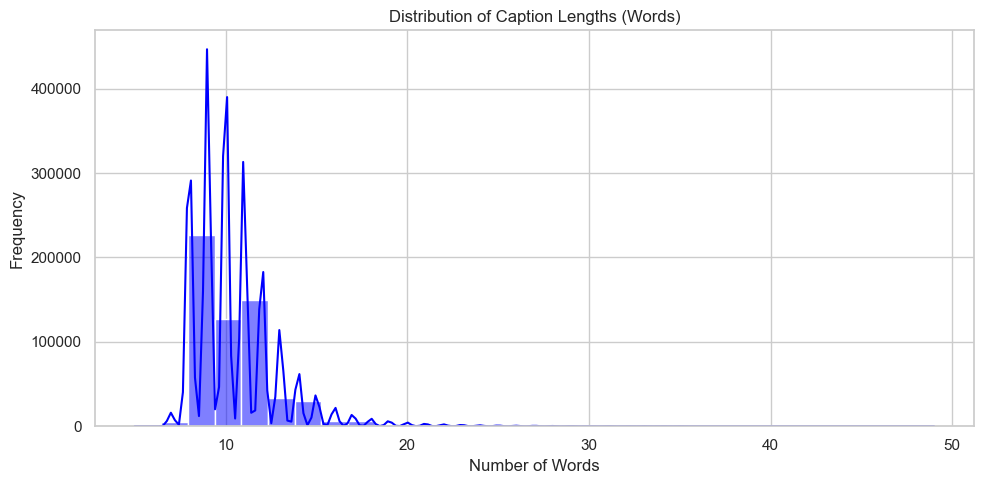

Generating Plot 2: Top 50 Words...


C:\Users\Quibix\AppData\Local\Temp\ipykernel_24656\3132879271.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts, y=words, palette='viridis')


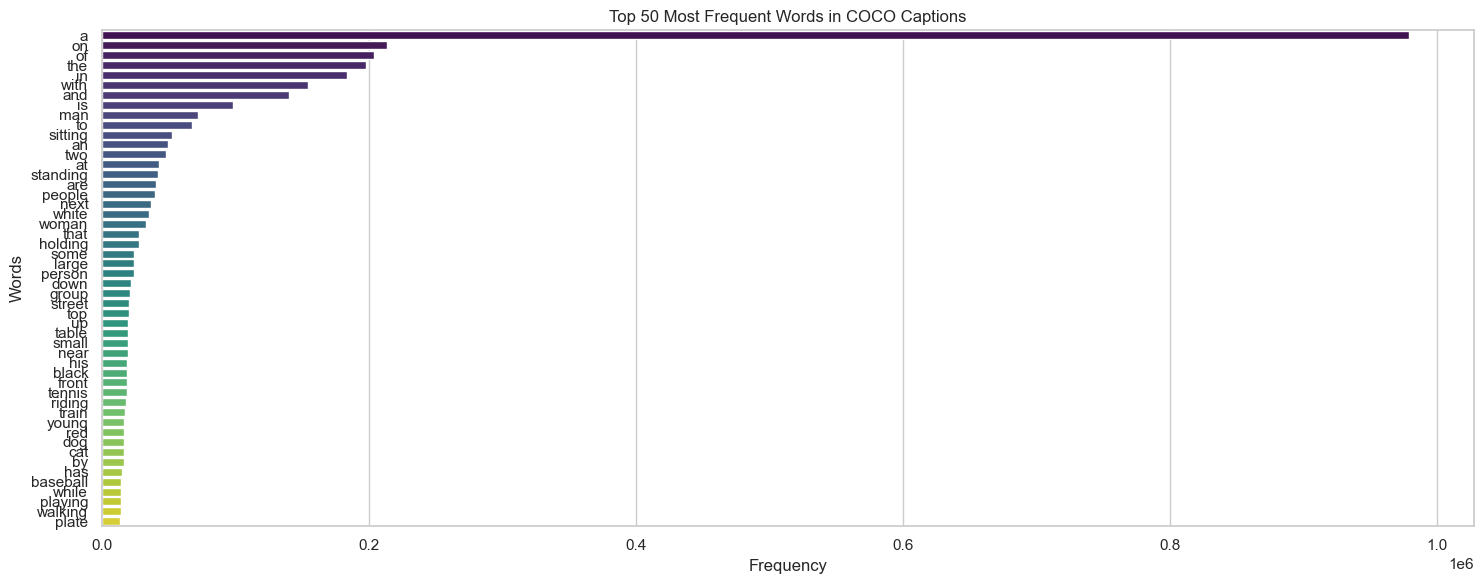

Generating Plot 3: POS Distribution (using a 1000 caption sample)...


LookupError: 
**********************************************************************
  Resource [93mpunkt_tab[0m not found.
  Please use the NLTK Downloader to obtain the resource:

  [31m>>> import nltk
  >>> nltk.download('punkt_tab')
  [0m
  For more information see: https://www.nltk.org/data.html

  Attempted to load [93mtokenizers/punkt_tab/english/[0m

  Searched in:
    - 'C:\\Users\\Quibix/nltk_data'
    - 'c:\\Users\\Quibix\\anaconda3\\nltk_data'
    - 'c:\\Users\\Quibix\\anaconda3\\share\\nltk_data'
    - 'c:\\Users\\Quibix\\anaconda3\\lib\\nltk_data'
    - 'C:\\Users\\Quibix\\AppData\\Roaming\\nltk_data'
    - 'C:\\nltk_data'
    - 'D:\\nltk_data'
    - 'E:\\nltk_data'
**********************************************************************


In [4]:
import json
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import os

# Set a nice style for the plots
sns.set_theme(style="whitegrid")

# 1. LOAD DATA (Use a sample to save memory, as the full file is 91MB)
annotation_file = "../data/annotations/captions_train2017.json"
print("Loading annotations...")
with open(annotation_file, 'r') as f:
    data = json.load(f)

# Extract captions and image IDs
annotations = data['annotations']
captions = [ann['caption'] for ann in annotations]

# --- PLOT 1: CAPTION LENGTH DISTRIBUTION ---
print("Generating Plot 1: Caption Lengths...")
caption_lengths = [len(c.split()) for c in captions]

plt.figure(figsize=(10, 5))
sns.histplot(caption_lengths, bins=30, kde=True, color='blue')
plt.title('Distribution of Caption Lengths (Words)')
plt.xlabel('Number of Words')
plt.ylabel('Frequency')
plt.tight_layout()
plt.savefig('../figures/caption_length_distribution.png')
plt.show()

# --- PLOT 2: MOST FREQUENT WORDS ---
print("Generating Plot 2: Top 50 Words...")
# Simple tokenization (lowercase and split)
all_words = []
for c in captions:
    all_words.extend(c.lower().split())

# Count frequencies
word_counts = Counter(all_words)
top_50_words = word_counts.most_common(50)

words = [w[0] for w in top_50_words]
counts = [w[1] for w in top_50_words]

plt.figure(figsize=(15, 6))
sns.barplot(x=counts, y=words, palette='viridis')
plt.title('Top 50 Most Frequent Words in COCO Captions')
plt.xlabel('Frequency')
plt.ylabel('Words')
plt.tight_layout()
plt.savefig('../figures/top_50_words.png')
plt.show()

# --- PLOT 3: POS (PART-OF-SPEECH) DISTRIBUTION ---
# If you don't have nltk installed, you can skip this or install it.
try:
    import nltk
    from nltk import pos_tag, word_tokenize
    # Download necessary NLTK data
    nltk.download('punkt', quiet=True)
    nltk.download('averaged_perceptron_tagger', quiet=True)
    
    print("Generating Plot 3: POS Distribution (using a 1000 caption sample)...")
    pos_tags = []
    # Use a sample for POS tagging because it's slow
    for c in captions[:1000]:
        tokens = word_tokenize(c)
        tagged = pos_tag(tokens)
        pos_tags.extend([tag for word, tag in tagged])
        
    pos_counts = Counter(pos_tags).most_common(10)
    pos_labels = [p[0] for p in pos_counts]
    pos_values = [p[1] for p in pos_counts]
    
    plt.figure(figsize=(10, 5))
    sns.barplot(x=pos_labels, y=pos_values, palette='magma')
    plt.title('Top 10 Part-of-Speech Tags (Sample of 1000 captions)')
    plt.xlabel('POS Tag')
    plt.ylabel('Frequency')
    plt.tight_layout()
    plt.savefig('../figures/pos_distribution.png')
    plt.show()
except ImportError:
    print("Skipping POS plot (nltk not installed).")

print("✅ All plots generated and saved to the '../figures/' folder!")

Loading object annotations (this is a large file)...
Generating Plot 4: Object Categories...


C:\Users\Quibix\AppData\Local\Temp\ipykernel_24656\3539092073.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_values, y=cat_names, palette='Blues_r')


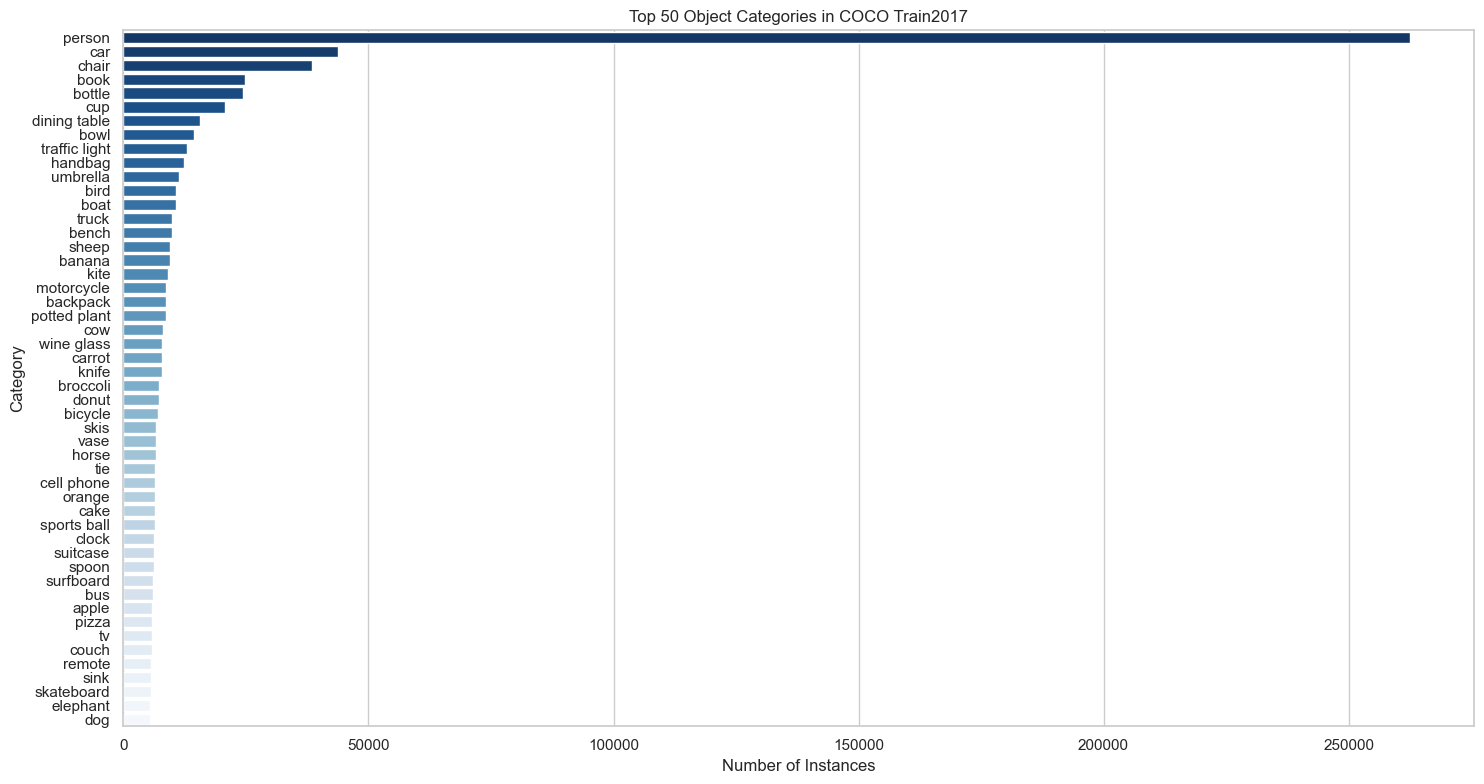

Generating Plot 5: Scene Complexity...


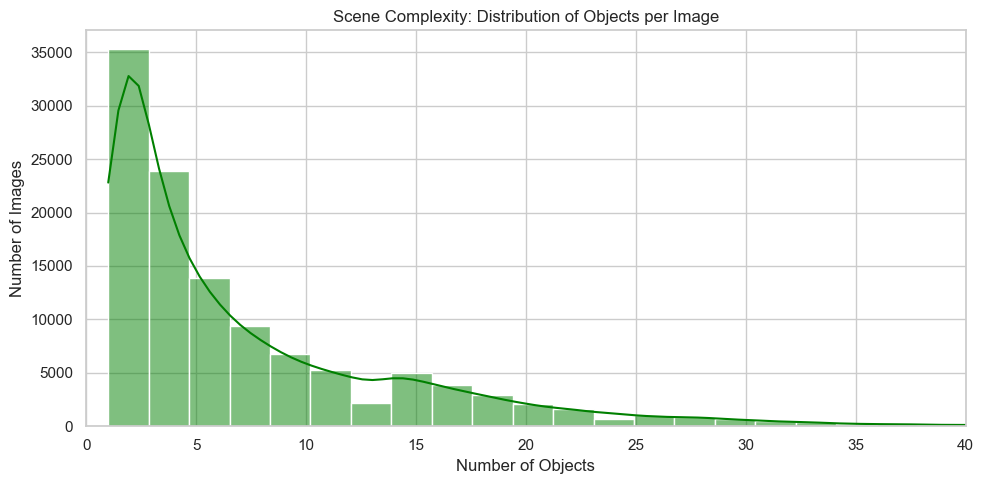

✅ Object plots generated and saved!


In [5]:
import json
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# 1. LOAD INSTANCES DATA (This might take a few seconds and use RAM)
instances_file = "../data/annotations/instances_train2017.json"
print("Loading object annotations (this is a large file)...")
with open(instances_file, 'r') as f:
    inst_data = json.load(f)

# --- PLOT 4: TOP 50 OBJECT CATEGORIES ---
print("Generating Plot 4: Object Categories...")
# Map category IDs to names
categories = {cat['id']: cat['name'] for cat in inst_data['categories']}
cat_counts = Counter([ann['category_id'] for ann in inst_data['annotations']])

# Get top 50
top_cats = cat_counts.most_common(50)
cat_names = [categories[c[0]] for c in top_cats]
cat_values = [c[1] for c in top_cats]

plt.figure(figsize=(15, 8))
sns.barplot(x=cat_values, y=cat_names, palette='Blues_r')
plt.title('Top 50 Object Categories in COCO Train2017')
plt.xlabel('Number of Instances')
plt.ylabel('Category')
plt.tight_layout()
plt.savefig('../figures/top_50_object_categories.png')
plt.show()

# --- PLOT 5: SCENE COMPLEXITY (OBJECTS PER IMAGE) ---
print("Generating Plot 5: Scene Complexity...")
# Count objects per image
objects_per_image = Counter([ann['image_id'] for ann in inst_data['annotations']])
obj_counts = list(objects_per_image.values())

plt.figure(figsize=(10, 5))
sns.histplot(obj_counts, bins=50, kde=True, color='green')
plt.title('Scene Complexity: Distribution of Objects per Image')
plt.xlabel('Number of Objects')
plt.ylabel('Number of Images')
plt.xlim(0, 40) # Limit x-axis to 40 to make the plot readable (outliers exist)
plt.tight_layout()
plt.savefig('../figures/scene_complexity_distribution.png')
plt.show()

print("✅ Object plots generated and saved!")

Loading object annotations...


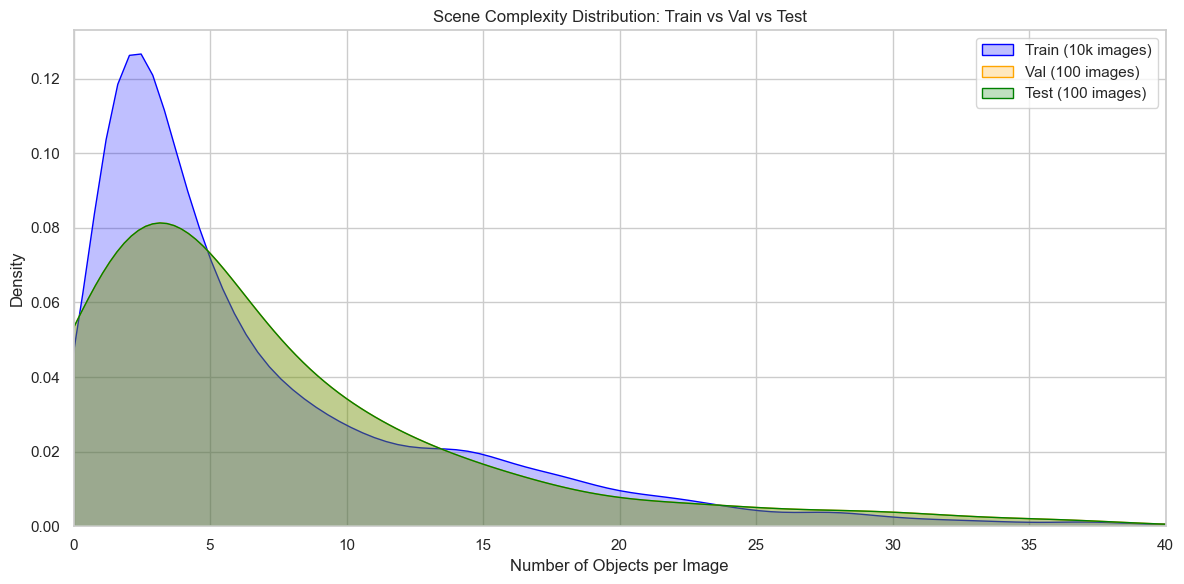

In [6]:
import json
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from pathlib import Path

# Set style
sns.set_theme(style="whitegrid")

# 1. Load the instances file to get objects per image
print("Loading object annotations...")
with open("../data/annotations/instances_train2017.json", 'r') as f:
    inst_data = json.load(f)

# Count objects per image
objects_per_image = Counter([ann['image_id'] for ann in inst_data['annotations']])

# 2. Load your frozen splits
with open("../data/splits/train_ids.json", "r") as f: train_ids = json.load(f)
with open("../data/splits/val_ids.json", "r") as f: val_ids = json.load(f)
with open("../data/splits/test_ids.json", "r") as f: test_ids = json.load(f)

# 3. Get scene complexity for each split
train_complexity = [objects_per_image.get(img_id, 0) for img_id in train_ids]
val_complexity = [objects_per_image.get(img_id, 0) for img_id in val_ids]
test_complexity = [objects_per_image.get(img_id, 0) for img_id in test_ids]

# 4. Plot the comparison
plt.figure(figsize=(12, 6))
sns.kdeplot(train_complexity, label='Train (10k images)', fill=True, color='blue')
sns.kdeplot(val_complexity, label='Val (100 images)', fill=True, color='orange')
sns.kdeplot(test_complexity, label='Test (100 images)', fill=True, color='green')

plt.title('Scene Complexity Distribution: Train vs Val vs Test')
plt.xlabel('Number of Objects per Image')
plt.ylabel('Density')
plt.xlim(0, 40) # Limit x-axis for readability
plt.legend()
plt.tight_layout()
plt.savefig('../figures/split_complexity_comparison.png')
plt.show()

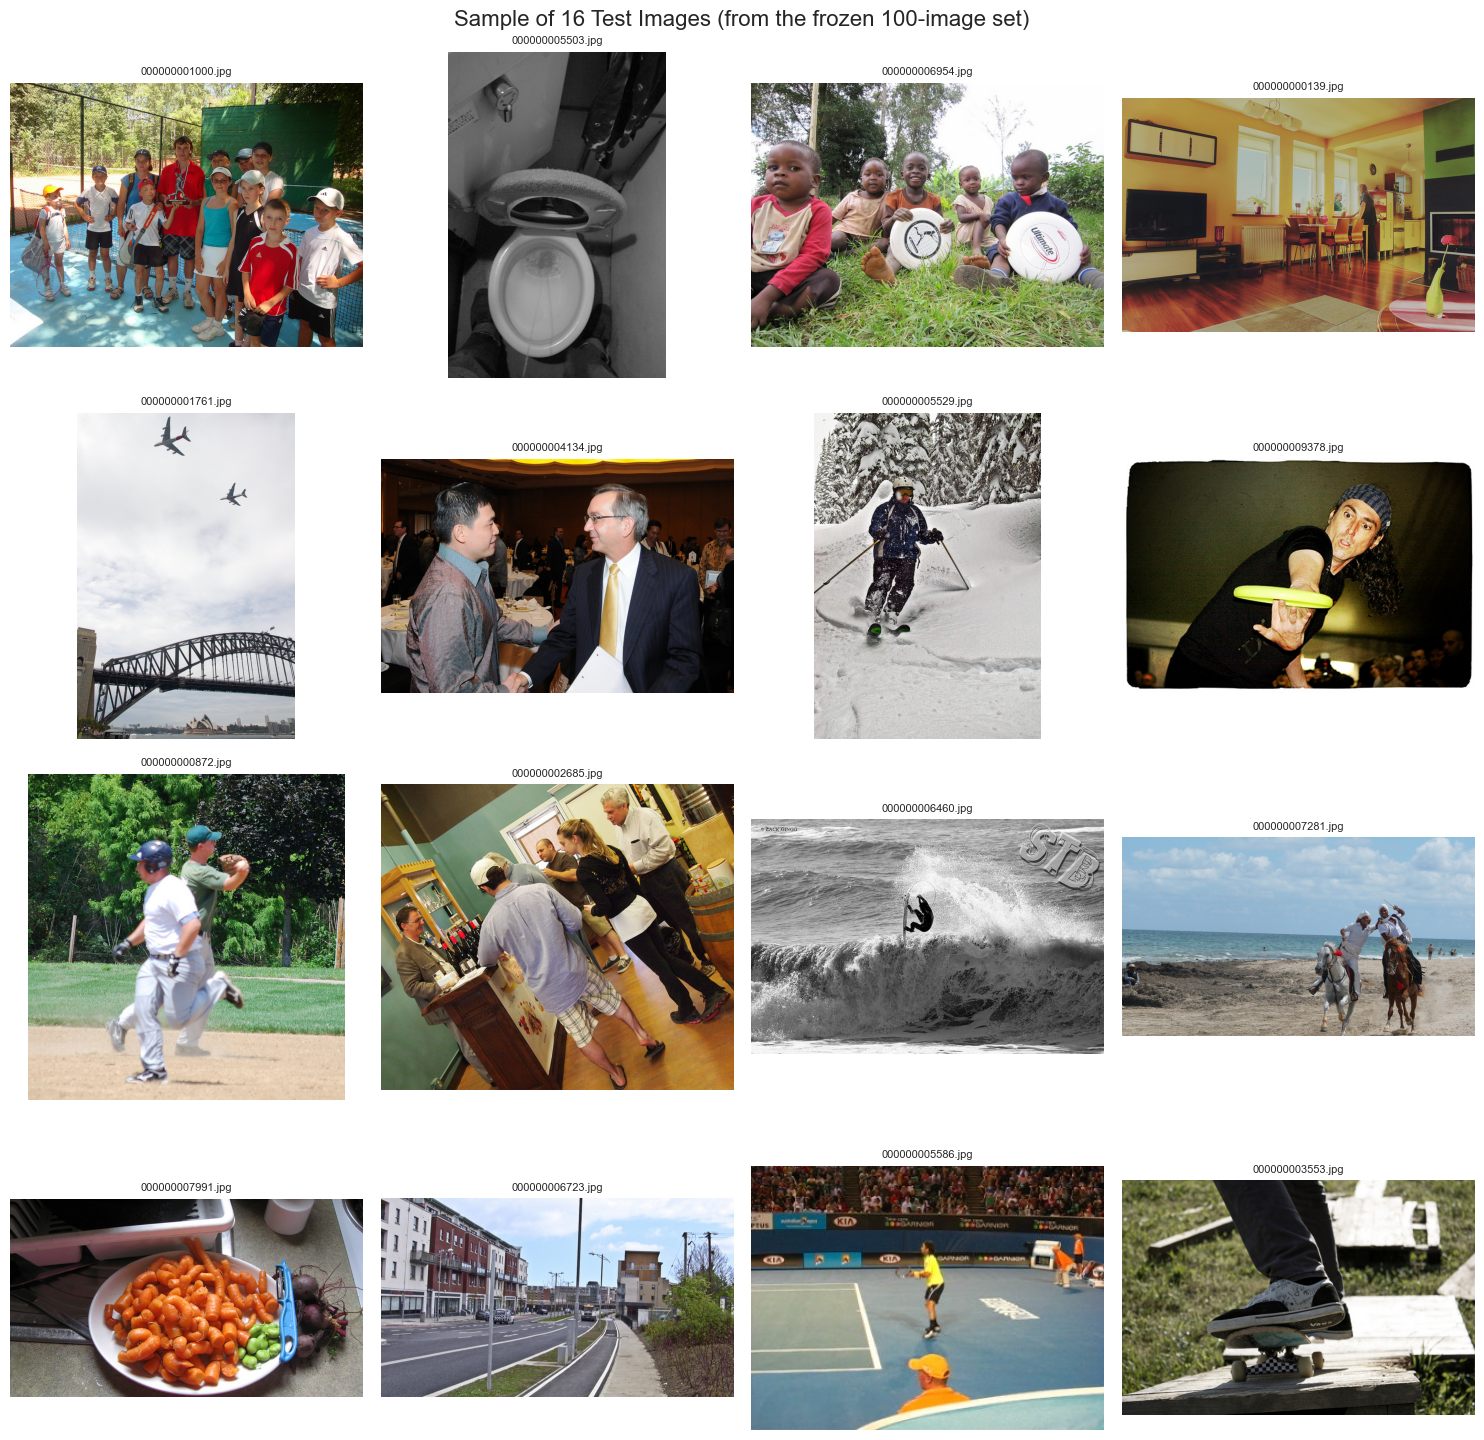

In [7]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import random

# Set up the path to your 100 test images
test_img_dir = Path("../data/test_subset_100")

# Get a list of all 100 images
# (Using rglob in case they are inside a subfolder from the zip)
all_images = list(test_img_dir.rglob("*.jpg"))

# Randomly select 16 images to display in a 4x4 grid
sample_images = random.sample(all_images, 16)

fig, axes = plt.subplots(4, 4, figsize=(15, 15))
axes = axes.flatten()

for i, img_path in enumerate(sample_images):
    img = Image.open(img_path)
    axes[i].imshow(img)
    axes[i].axis('off')
    axes[i].set_title(img_path.name, fontsize=8)

plt.suptitle("Sample of 16 Test Images (from the frozen 100-image set)", fontsize=16)
plt.tight_layout()
plt.savefig('../figures/test_set_sample_grid.png')
plt.show()

## Conclusion

This phase focused on preparing and organizing the MS-COCO dataset for the next stages of the Metadata-Filtered RAG project.

The image preprocessing process ensured that all images were correctly oriented and converted into RGB format. In addition, a grayscale preprocessing stage was performed by converting the RGB images into grayscale format using the Pillow library. Both image representations were saved in separate directories, preserving the original RGB data.

The caption preprocessing step preserved the original captions and generated cleaned versions to provide a consistent textual representation. Object annotations were also integrated to enrich the metadata with visual information.

Two metadata datasets were then prepared. The original `metadata.csv` contains image information, RGB image paths, original and cleaned captions, and object annotations. The additional `metadata_grayscale.csv` preserves all the original metadata information while adding the grayscale image paths and color modes. Separate preprocessing reports were also generated for RGB and Grayscale images.

The dataset contains 10,099 images, including 9,999 training images and 100 validation images, with a total of 50,521 captions and 72,998 object annotations. All 10,099 grayscale images were successfully generated and verified. The verification checks confirmed unique image IDs, no missing grayscale files, and consistent image modes. The original RGB metadata and annotations were also preserved.

As a result, the dataset is now cleaned, preprocessed, organized, and available in two image representations: RGB and Grayscale. Both versions are ready to be used in the next stages of the Metadata-Filtered RAG project, particularly the embedding preparation stage and subsequent retrieval experiments.